In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('water_potability.csv')
df

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [3]:
df.duplicated().sum()

np.int64(0)

In [4]:
for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               3276 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          3276 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3276 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [5]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.036752,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,333.073546,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
X = df.drop('Potability',axis=1)
y = df['Potability']


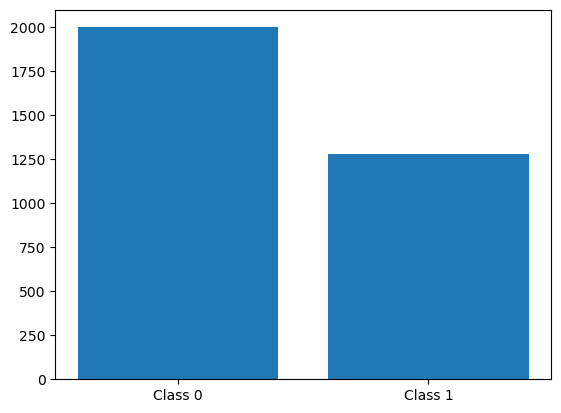

In [7]:
counts = y.value_counts()
plt.bar(['Class 0','Class 1'],counts)
plt.show()

In [8]:
from sklearn.model_selection import RandomizedSearchCV
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rf_params = {
    'n_estimators' : [50,100,150,200],
    'max_depth' : [3,5,10],
    'min_samples_split' : [2,5],
    'min_samples_leaf' : [1,2,5]
}
rf_grid = RandomizedSearchCV(estimator=RandomForestClassifier(),param_distributions=rf_params,cv=5,n_jobs=-1,n_iter=10,random_state=42)
rf_grid.fit(X_train_scaled,y_train)
rf_pred = rf_grid.predict(X_test_scaled)

In [9]:
from sklearn.metrics import accuracy_score,f1_score,recall_score,confusion_matrix,precision_score
rf_acc = accuracy_score(y_test,rf_pred)
rf_f1 = f1_score(y_test,rf_pred)
rf_rec = f1_score(y_test,rf_pred)
rf_prec = precision_score(y_test,rf_pred)
print(rf_acc)
print(rf_f1)
print(rf_rec)
print(rf_prec)


0.6859756097560976
0.3795180722891566
0.3795180722891566
0.7159090909090909


In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
knn_params = {
    'n_neighbors' : [3,5,7,9,11],
    'weights' : ['uniform','distance'],
    'metric' : ['euclidean','manhattan']
}
knn_grid = GridSearchCV(estimator=KNeighborsClassifier(),n_jobs=-1,cv=5,param_grid=knn_params)
knn_grid.fit(X_train_scaled,y_train)
knn_pred = knn_grid.predict(X_test_scaled)
knn_acc = accuracy_score(y_test,knn_pred)
knn_f1 = f1_score(y_test,knn_pred)
knn_prec = precision_score(y_test,knn_pred)
knn_rec = recall_score(y_test,knn_pred)

print(knn_acc)
print(knn_prec)
print(knn_rec)
print(knn_f1)


0.6478658536585366
0.5436241610738255
0.3319672131147541
0.4122137404580153


In [11]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote,y_train_smote = smote.fit_resample(X_train_scaled,y_train)


In [12]:
tree_params = {
    'max_depth' : [3,5,10],
    'criterion' : ['gini','entropy'],
    'min_samples_split' : [2,5],
    'min_samples_leaf' : [1,2,5]
}
tree_grid = GridSearchCV(estimator=DecisionTreeClassifier(),param_grid=tree_params,cv=5,n_jobs=-1)
tree_grid.fit(X_train_smote,y_train_smote)
tree_pred = tree_grid.predict(X_test_scaled)

tree_acc = accuracy_score(y_test,tree_pred)
tree_f1 = f1_score(y_test,tree_pred)
tree_prec = precision_score(y_test,tree_pred)
tree_rec = recall_score(y_test,tree_pred)

print(tree_acc)
print(tree_prec)
print(tree_rec)
print(tree_f1)

0.5655487804878049
0.43952802359882004
0.610655737704918
0.5111492281303602


In [13]:
from scipy.stats import loguniform
svm_params = {
    'C': loguniform(0.1, 10),
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'kernel': ['rbf', 'linear']
}

svm_search = RandomizedSearchCV(
    estimator=SVC(),
    param_distributions=svm_params,
    n_iter=5,
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=2
)
svm_search.fit(X_train_smote,y_train_smote)
svm_pred = svm_search.predict(X_test_scaled)
svm_acc = accuracy_score(y_test,svm_pred)
svm_f1 = f1_score(y_test,svm_pred)
svm_prec = precision_score(y_test,svm_pred)
svm_rec = recall_score(y_test,svm_pred)

print(svm_acc)
print(svm_prec)
print(svm_rec)
print(svm_f1)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
0.6219512195121951
0.49295774647887325
0.5737704918032787
0.5303030303030303


In [14]:
logi_model = LogisticRegression(class_weight='balanced')
logi_model.fit(X_train_smote,y_train_smote)
logi_pred = logi_model.predict(X_test_scaled)
logi_acc = accuracy_score(y_test,logi_pred)
logi_f1 = f1_score(y_test,logi_pred)
logi_prec = precision_score(y_test,logi_pred)
logi_rec = recall_score(y_test,logi_pred)

print(logi_acc)
print(logi_prec)
print(logi_rec)
print(logi_f1)

0.5030487804878049
0.370253164556962
0.47950819672131145
0.41785714285714287


In [15]:
import joblib
joblib.dump(svm_search,'svm_model.pkl')

['svm_model.pkl']

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    k_mean_s = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = k_mean_s.fit_predict(X_train_smote)
    score = silhouette_score(X_train_smote, labels)
    print(f'{k}   {score}')

2   0.08718544780055273
3   0.07747891601091093
4   0.07672369238447213
5   0.07765269410490949
6   0.07631756167102084
7   0.07620947257753719
8   0.07798170046738369
9   0.07689464546240518
10   0.08055195296707476


In [17]:
final_model = KMeans(n_clusters=2,n_init=10,random_state=42)
cluster = final_model.fit_predict(X_train_smote)
smote_df = pd.DataFrame(X_train_smote, columns=X.columns)
smote_df['Cluster'] = cluster
smote_df['Potability'] = y_train_smote.values

In [18]:
#Feature Importances
winning_model = rf_grid.best_estimator_
raw_scores = winning_model.feature_importances_
importance_dict = {
    'Water_Features' : X.columns,
    'Impact_Scores' : raw_scores
}
feature_importance_df = pd.DataFrame(importance_dict)
feature_importance_df = feature_importance_df.sort_values(by='Impact_Scores',ascending=False)
feature_importance_df

,Water_Features,Impact_Scores
4,Sulfate,0.164115
0,ph,0.149019
1,Hardness,0.128803
3,Chloramines,0.115069
2,Solids,0.112208
7,Trihalomethanes,0.087151
6,Organic_carbon,0.085352
5,Conductivity,0.083385
8,Turbidity,0.074898


In [19]:
#Isolation Forest
from sklearn.ensemble import IsolationForest
iso_forest = IsolationForest(contamination=0.05,random_state=42)
anomalies = iso_forest.fit_predict(X_train_scaled)
anomaly_df = pd.DataFrame(X_train,columns=X.columns)
anomaly_df['Is_Anomaly'] = anomalies
anomaly_df['Potable_Water'] = y_train.values
false_alarms = anomaly_df[(anomaly_df['Is_Anomaly']==-1) & (anomaly_df['Potable_Water'] ==1)]
print(f'No of False Alarms: {len(false_alarms)}')
false_alarms

No of False Alarms: 69


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Is_Anomaly,Potable_Water
789,5.361212,171.315543,24709.728858,4.184891,366.814979,490.658747,15.122672,33.119613,1.812529,-1,1
366,4.037288,291.461897,52318.917298,7.779459,333.073546,401.204271,16.542921,87.814800,3.045049,-1,1
810,0.989912,133.216942,16922.853899,9.293289,444.375731,322.291191,10.430076,43.578466,5.160604,-1,1
351,8.848586,188.919983,32033.332019,13.127000,182.397370,479.791975,12.070444,77.671337,4.014682,-1,1
365,4.788861,234.893703,28174.620516,10.850036,187.424131,444.854321,11.784799,89.010974,2.896852,-1,1
...,...,...,...,...,...,...,...,...,...,...,...
2343,2.538116,100.806520,19872.854854,5.014023,418.000000,420.830866,13.980891,85.943192,2.840097,-1,1
2777,5.141507,111.994028,11288.634718,5.841750,389.225673,315.229665,12.982476,81.159239,4.510578,-1,1
2363,6.073685,140.926196,11795.313580,9.128422,437.647163,413.075820,14.934850,48.018966,5.249070,-1,1
3236,4.767472,256.449917,48007.868134,5.773180,333.073546,590.429550,16.541561,44.938586,3.893378,-1,1


In [20]:
#PCA 
from sklearn.decomposition import PCA
pca = PCA(n_components=3,random_state=42)
pca_Data = pca.fit_transform(X_train_scaled)
pca_df = pd.DataFrame(pca_Data,columns=['PCA1','PCA2','PCA3'])
pca_df['Potabality'] = y_train.values
pca_df['Is_Anomaly'] = anomalies
pca_df.to_csv('Visualisation_Data_Of_Water.csv',index=False)

In [21]:
joblib.dump(scaler,'scaler.pkl')

['scaler.pkl']

In [22]:
joblib.dump(iso_forest,'iso_forest.pkl')

['iso_forest.pkl']